In [24]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import tensorflow as tf
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.layers import Dense
from tensorflow.keras.models import Sequential

prepare the data

In [25]:
tf.random.set_seed(42)
X,Y=load_iris(return_X_y=True)
X=X[:100]
Y=Y[:100]
scaler=StandardScaler()
X_Train,X_Test,Y_Train,Y_Test=train_test_split(X,Y,test_size=0.2,random_state=42)
X_Train=scaler.fit_transform(X_Train)
X_Test=scaler.transform(X_Test)

Mini-batch SGD

In [33]:
model=Sequential([Dense(1,activation='sigmoid')])
model.compile(optimizer=SGD(learning_rate=0.1),loss='binary_crossentropy',metrics=['accuracy'])
history=model.fit(X_Train,Y_Train,epochs=50,batch_size=16,verbose=0)
pre=model.predict(X_Test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


In [34]:
test_loss, test_acc = model.evaluate(X_Test, Y_Test, verbose=0)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc * 100:.2f}%")

Test Loss: 0.0150
Test Accuracy: 100.00%


In [35]:
test_loss, test_acc = model.evaluate(X_Test, Y_Test, verbose=0)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc * 100:.2f}%")

Test Loss: 0.0150
Test Accuracy: 100.00%


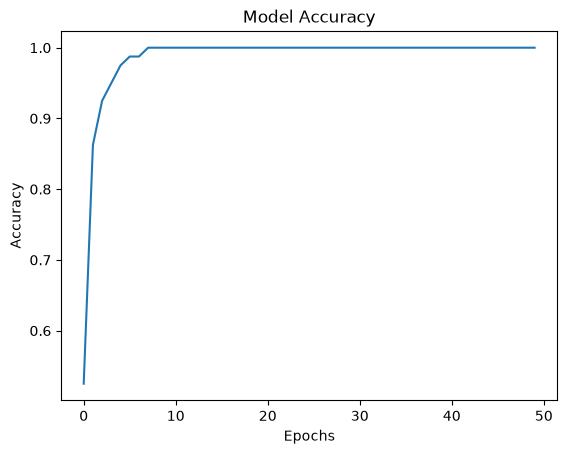

In [36]:
plt.plot(history.history['accuracy'])
plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.show()

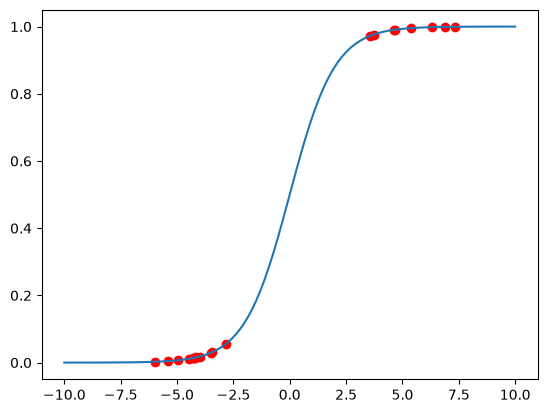

In [37]:
w, b = model.layers[0].get_weights()   # استخراج الأوزان من النموذج
z_test = np.dot(X_Test, w) + b         # حساب z لبيانات الاختبار

z_line = np.linspace(-10, 10, 100)     # نقاط لرسم منحنى السيجمويد السلس
sigmoid = 1 / (1 + np.exp(-z_line))

plt.plot(z_line, sigmoid, label="Sigmoid Curve")
plt.scatter(z_test, pre, color='red', label="Test Predictions")
